<a href="https://colab.research.google.com/github/Dheepdata/DHEEPDATA/blob/main/ESol.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Downloading necessary libraries

In [ ]:
!pip install rdkit-pypi

In [ ]:
!pip install torch torchvision torchaudio


In [ ]:
# Install PyTorch Geometric dependencies and core
!pip install torch-scatter -f https://data.pyg.org/whl/torch-2.2.0+cpu.html
!pip install torch-sparse -f https://data.pyg.org/whl/torch-2.2.0+cpu.html
!pip install torch-cluster -f https://data.pyg.org/whl/torch-2.2.0+cpu.html
!pip install torch-spline-conv -f https://data.pyg.org/whl/torch-2.2.0+cpu.html
!pip install torch-geometric


Looking in links: https://data.pyg.org/whl/torch-2.2.0+cpu.html
Looking in links: https://data.pyg.org/whl/torch-2.2.0+cpu.html
Looking in links: https://data.pyg.org/whl/torch-2.2.0+cpu.html
Looking in links: https://data.pyg.org/whl/torch-2.2.0+cpu.html


In [ ]:
import torch_geometric

In [ ]:
import torch
import pandas as pd

import matplotlib.pyplot as plt
import rdkit
from rdkit import Chem
from rdkit.Chem import Draw
from torch_geometric.datasets import MoleculeNet

## Downloding the dataset & analysing

In [ ]:
data = MoleculeNet(root=".", name="ESOL")
data


ESOL(1128)

In [ ]:
data[0]

Data(x=[8, 9], edge_index=[2, 16], edge_attr=[16, 3], smiles='C=Cc1ccccc1', y=[1, 1])

In [ ]:
len(data)

1128

In [ ]:
for key, item in data[0]:
    print(f'{key} found in data')
    print(f'{item}')

x found in data
tensor([[6, 0, 3, 5, 2, 0, 3, 0, 0],
        [6, 0, 3, 5, 1, 0, 3, 0, 0],
        [6, 0, 3, 5, 0, 0, 3, 1, 1],
        [6, 0, 3, 5, 1, 0, 3, 1, 1],
        [6, 0, 3, 5, 1, 0, 3, 1, 1],
        [6, 0, 3, 5, 1, 0, 3, 1, 1],
        [6, 0, 3, 5, 1, 0, 3, 1, 1],
        [6, 0, 3, 5, 1, 0, 3, 1, 1]])
edge_index found in data
tensor([[0, 1, 1, 2, 2, 2, 3, 3, 4, 4, 5, 5, 6, 6, 7, 7],
        [1, 0, 2, 1, 3, 7, 2, 4, 3, 5, 4, 6, 5, 7, 2, 6]])
edge_attr found in data
tensor([[ 2,  0,  1],
        [ 2,  0,  1],
        [ 1,  0,  1],
        [ 1,  0,  1],
        [12,  0,  1],
        [12,  0,  1],
        [12,  0,  1],
        [12,  0,  1],
        [12,  0,  1],
        [12,  0,  1],
        [12,  0,  1],
        [12,  0,  1],
        [12,  0,  1],
        [12,  0,  1],
        [12,  0,  1],
        [12,  0,  1]])
smiles found in data
C=Cc1ccccc1
y found in data
tensor([[-2.8200]])


## Splitting as training and testing dataset

In [ ]:
data = data.shuffle()
train_data = data[:900]
test_data = data[900:]
train_data, test_data

(ESOL(900), ESOL(228))

In [ ]:
data[0], data[1], data[2], data[3], data[4]

(Data(x=[8, 9], edge_index=[2, 16], edge_attr=[16, 3], smiles='C=Cc1ccccc1', y=[1, 1]),
 Data(x=[5, 9], edge_index=[2, 8], edge_attr=[8, 3], smiles='ClCC(Cl)Cl', y=[1, 1]),
 Data(x=[11, 9], edge_index=[2, 22], edge_attr=[22, 3], smiles='CCCCCc1ccccc1', y=[1, 1]),
 Data(x=[8, 9], edge_index=[2, 16], edge_attr=[16, 3], smiles='Clc1ccccc1Br', y=[1, 1]),
 Data(x=[19, 9], edge_index=[2, 38], edge_attr=[38, 3], smiles='CCc1cccc(C)c1N(C(C)COC)C(=O)CCl ', y=[1, 1]))

In [ ]:
print(f"Number of edge features: {data.num_edge_features}")
print(f"Number of node features: {data.num_node_features}")
print(f"Number of features: {data.num_features}")
print(f"Number of classes: {data.num_classes}")
print(f"Length of esol dataset:{data.len}")


Number of edge features: 3
Number of node features: 9
Number of features: 9
Number of classes: 734
Length of esol dataset:<bound method InMemoryDataset.len of ESOL(1128)>


In [ ]:
print(f"Number of nodes:{data[0].num_nodes}")
print(f"Number ofedges:{data[0].num_edges}")
data[0].x, data[0].y


Number of nodes:8
Number ofedges:16


(tensor([[6, 0, 3, 5, 2, 0, 3, 0, 0],
         [6, 0, 3, 5, 1, 0, 3, 0, 0],
         [6, 0, 3, 5, 0, 0, 3, 1, 1],
         [6, 0, 3, 5, 1, 0, 3, 1, 1],
         [6, 0, 3, 5, 1, 0, 3, 1, 1],
         [6, 0, 3, 5, 1, 0, 3, 1, 1],
         [6, 0, 3, 5, 1, 0, 3, 1, 1],
         [6, 0, 3, 5, 1, 0, 3, 1, 1]]),
 tensor([[-2.8200]]))

In [ ]:
data[0].edge_attr

tensor([[ 2,  0,  1],
        [ 2,  0,  1],
        [ 1,  0,  1],
        [ 1,  0,  1],
        [12,  0,  1],
        [12,  0,  1],
        [12,  0,  1],
        [12,  0,  1],
        [12,  0,  1],
        [12,  0,  1],
        [12,  0,  1],
        [12,  0,  1],
        [12,  0,  1],
        [12,  0,  1],
        [12,  0,  1],
        [12,  0,  1]])

In [ ]:
data[0].edge_index

tensor([[0, 1, 1, 2, 2, 2, 3, 3, 4, 4, 5, 5, 6, 6, 7, 7],
        [1, 0, 2, 1, 3, 7, 2, 4, 3, 5, 4, 6, 5, 7, 2, 6]])

In [ ]:
data[0].has_isolated_nodes()

False

In [ ]:
data[0].has_self_loops()


False

In [ ]:
data[0].is_directed()

False

In [ ]:
data[0].is_undirected()

True

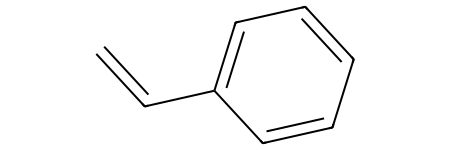

In [ ]:
molecule  = Chem.MolFromSmiles(data[0].smiles)
molecule

In [ ]:
data.x=data.x.float()

In [ ]:
data.y = data.y.float()

In [ ]:
data.edge_index = data.edge_index.long()

## Using dataloader to split as batches

In [ ]:
from torch_geometric.loader import DataLoader


In [ ]:
train_loader = DataLoader(train_data, batch_size = 64, shuffle = True)
test_loader = DataLoader(test_data, batch_size = 64, shuffle = False)
print(".........Train_dataset.......")
train_batches = []
for batch in train_loader:
  train_batches.append(batch.num_graphs)
print(train_batches)

print(".........Test_dataset.......")
test_batches = []
for batch in test_loader:
  test_batches.append(batch.num_graphs)
print(test_batches)


.........Train_dataset.......
[64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 4]
.........Test_dataset.......
[64, 64, 64, 36]


# Base Model: Model_0

In [ ]:
from torch import nn
from torch.nn import Linear
import torch.nn.functional as F
from torch_geometric.nn import GCNConv
from torch_geometric.nn import global_mean_pool as gmp, global_max_pool as gap

In [ ]:
class GCNModelV0(torch.nn.Module):
  def __init__(self, input_unit:int, hidden_unit:int, output_unit:int):
    super().__init__()
    self.conv1 = GCNConv(input_unit, hidden_unit)
    self.conv2 = GCNConv(hidden_unit, hidden_unit)
    self.conv3 = GCNConv(hidden_unit, hidden_unit)
    self.conv4 = GCNConv(hidden_unit, hidden_unit)
    self.linear = Linear(hidden_unit*2, 1)


  def forward(self, x, edge_index, batch):
    x = self.conv1(x, edge_index)
    x = F.tanh(x)
    x = self.conv2(x, edge_index)
    x = F.tanh(x)
    x = self.conv3(x, edge_index)
    x = F.tanh(x)
    x = self.conv4(x, edge_index)
    x = F.tanh(x)

    x = torch.cat([gmp(x, batch),
                            gap(x, batch)], dim=1)



    #x = F.dropout(x, p=0.5, training=self.training)

    x = self.linear(x)
    return x




torch.manual_seed(42)
model_0 = GCNModelV0(input_unit= data.num_node_features, hidden_unit= 64, output_unit= 1)
print (model_0)

GCNModelV0(
  (conv1): GCNConv(9, 64)
  (conv2): GCNConv(64, 64)
  (conv3): GCNConv(64, 64)
  (conv4): GCNConv(64, 64)
  (linear): Linear(in_features=128, out_features=1, bias=True)
)


In [ ]:
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(params = model_0.parameters(), lr = 0.0007)

In [ ]:
from timeit import default_timer as timer
def print_train_time(start: float, end: float):
    train_time =  end - start
    print(f"Total time taken for training: {train_time:.6f}seconds")
    return train_time

In [ ]:
def train_loop(model: torch.nn.Module,
               dataloader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               optimizer: torch.optim.Optimizer):
    train_loss = 0

    for batch in train_loader:
        model.train()

        ##Forwars pass
        y_pred = model(batch.x.float(), batch.edge_index, batch.batch)

        ## Calculate the loss
        loss = loss_fn(y_pred, batch.y.float())
        train_loss += loss


        ## Optimizer zero grad
        optimizer.zero_grad()

        ## Loss backward
        loss.backward()

        ## optimer step
        optimizer.step()

    train_loss /= len(train_loader)

    print(f" Train loss: {train_loss}")

In [ ]:
def test_loop(model: torch.nn.Module,
              dataloader: torch.utils.data.DataLoader,
              loss_fn: torch.nn.Module,
              optimizer: torch.optim.Optimizer):
    test_loss = 0

    for batch in test_loader:

        test_pred = model(batch.x.float(), batch.edge_index, batch.batch)

        ## Calculate loss
        loss = loss_fn(test_pred, batch.y.float())
        test_loss += loss


    test_loss /= len(test_loader)

    print(f"Test_loss: {test_loss}")


In [ ]:
from tqdm.auto import tqdm ## FOR KEEPING THE progress bar
torch.manual_seed(42)
start_time = timer()
epochs = 20000

for epoch in tqdm(range(epochs)):
  if epoch % 1000 == 0:
    print(f"Epoch: {epoch}------------")
    train_loop(model_0, train_loader, loss_fn, optimizer)


    model_0.eval()
    with torch.inference_mode():
        test_loop(model_0, test_loader, loss_fn, optimizer)

end_time = timer()
total_time = end_time - start_time
print(f"The total time taken for the model to run is: {total_time}")



  0%|          | 0/20000 [00:00<?, ?it/s]

Epoch: 0------------
 Train loss: 8.827252388000488
Test_loss: 5.212255477905273
Epoch: 1000------------
 Train loss: 4.506620407104492
Test_loss: 4.400763988494873
Epoch: 2000------------
 Train loss: 4.4284796714782715
Test_loss: 4.338366508483887
Epoch: 3000------------
 Train loss: 4.455324649810791
Test_loss: 4.3705735206604
Epoch: 4000------------
 Train loss: 4.3921685218811035
Test_loss: 4.30308198928833
Epoch: 5000------------
 Train loss: 4.113972187042236
Test_loss: 4.271231651306152
Epoch: 6000------------
 Train loss: 4.131653308868408
Test_loss: 4.240538120269775
Epoch: 7000------------
 Train loss: 4.768499851226807
Test_loss: 4.170040130615234
Epoch: 8000------------
 Train loss: 4.173765659332275
Test_loss: 4.066279411315918
Epoch: 9000------------
 Train loss: 4.153259754180908
Test_loss: 3.9861814975738525
Epoch: 10000------------
 Train loss: 3.729588031768799
Test_loss: 3.837322235107422
Epoch: 11000------------
 Train loss: 3.7009966373443604
Test_loss: 3.76170492

# Model_01: First updation of the baseline model